# 2. Exploratory data analysis and preprocessing

Run notebook 1 first. Use development data only for EDA and fitted preprocessing.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import OneHotEncoder, StandardScaler

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
if not (ROOT / 'data/processed/cohort.csv').exists():
    raise FileNotFoundError('Run notebook 1 from the project folder first.')

SEED = json.loads((ROOT / 'config.json').read_text())['seed']
OUT = ROOT / 'notebooks' / 'outputs'
for folder in ['figures', 'tables']:
    (OUT / folder).mkdir(parents=True, exist_ok=True)
pd.set_option('display.max_columns', 12)
pd.set_option('display.precision', 4)
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})
BLUE, ORANGE = '#246b83', '#c26b32'

## Data: use the development partition

Load development encounters. Remove identifiers, outcomes, and split metadata from the predictors.

In [2]:
cohort = pd.read_csv(
    ROOT / 'data/processed/cohort.csv',
    keep_default_na=False, na_values=['?'], low_memory=False,
)
assert cohort.groupby('patient_nbr')['split'].nunique().eq(1).all()
dev = cohort.loc[cohort['split'].eq('development')].reset_index(drop=True)
excluded_columns = ['encounter_id', 'patient_nbr', 'readmitted', 'target', 'split', 'partition_fold']
X = dev.drop(columns=excluded_columns).copy()
y = dev['target'].copy()
numeric_features = [
    'time_in_hospital', 'num_lab_procedures', 'num_procedures',
    'num_medications', 'number_outpatient', 'number_emergency',
    'number_inpatient', 'number_diagnoses',
]
print(f'{len(dev):,} development encounters, {dev.patient_nbr.nunique():,} patients')
print(f'{X.shape[1]} candidate predictors: {len(numeric_features)} numerical and {X.shape[1] - len(numeric_features)} categorical')
display(X[['age', 'time_in_hospital', 'number_inpatient', 'A1Cresult', 'medical_specialty']].head())

59,670 development encounters, 41,960 patients
47 candidate predictors: 8 numerical and 39 categorical


,age,time_in_hospital,number_inpatient,A1Cresult,medical_specialty
0,[0-10),1,0,None,Pediatrics-Endocrinology
1,[10-20),3,0,None,NaN
2,[30-40),2,0,None,NaN
3,[40-50),1,0,None,NaN
4,[70-80),5,0,None,NaN


## Results: class balance and missing values

Check the class proportions and missing values. Count laboratory `None` and coded unknown values separately.

,missing_count,missing_percent
feature,,
weight,57765,96.81
medical_specialty,29215,48.96
payer_code,23626,39.59
race,1344,2.25
diag_3,831,1.39
diag_2,212,0.36
diag_1,15,0.03


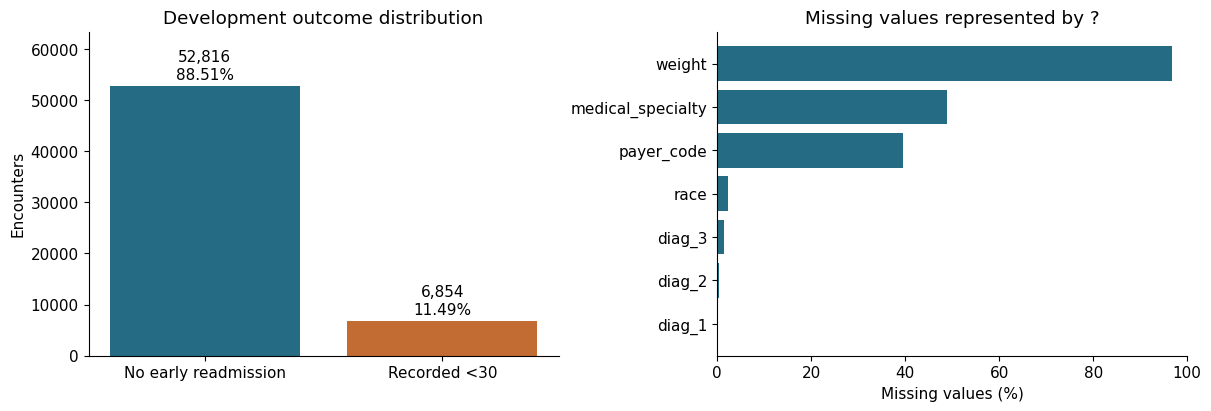

In [3]:
class_counts = y.value_counts().reindex([0, 1])
missingness = pd.DataFrame({
    'missing_count': X.isna().sum(),
    'missing_percent': X.isna().mean() * 100,
}).sort_values('missing_percent', ascending=False)
missingness.index.name = 'feature'
display(missingness.loc[missingness.missing_count.gt(0)].round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout='constrained')
axes[0].bar(['No early readmission', 'Recorded <30'], class_counts, color=[BLUE, ORANGE])
for i, count in enumerate(class_counts):
    axes[0].text(i, count + class_counts.max() * .025, f'{count:,}\n{count / len(y):.2%}', ha='center')
axes[0].set(title='Development outcome distribution', ylabel='Encounters', ylim=(0, class_counts.max() * 1.2))
missing_plot = missingness.loc[missingness.missing_count.gt(0)].iloc[::-1]
axes[1].barh(missing_plot.index, missing_plot.missing_percent, color=BLUE)
axes[1].set(title='Missing values represented by ?', xlabel='Missing values (%)', xlim=(0, 100))
fig.savefig(OUT / 'figures/01_class_balance_missingness.png', dpi=150, bbox_inches='tight')
plt.show()

Early readmission occurs in 11.49% of encounters, so accuracy alone can be misleading. Weight is 96.81% missing. Keep missing medical specialty and payer values as explicit categories.

In [4]:
lab_categories = []
for name in ['A1Cresult', 'max_glu_serum']:
    for category, count in X[name].fillna('Missing').value_counts().items():
        lab_categories.append({
            'feature': name, 'category': category,
            'encounters': count, 'percent': count / len(X) * 100,
        })
lab_categories = pd.DataFrame(lab_categories)
display(lab_categories.round(2))

unknown_codes = {
    'admission_type_id': [5, 6, 8],
    'admission_source_id': [9, 15, 17, 20, 21],
    'discharge_disposition_id': [18, 25, 26],
}
coded_unknowns = pd.DataFrame([
    {'feature': name, 'encounters': X[name].isin(codes).sum(),
     'percent': X[name].isin(codes).mean() * 100}
    for name, codes in unknown_codes.items()
])
display(coded_unknowns.round(2))
print('Unknown/Invalid gender entries in development:', X.gender.eq('Unknown/Invalid').sum())

,feature,category,encounters,percent
0,A1Cresult,None,49453,82.88
1,A1Cresult,>8,4986,8.36
2,A1Cresult,Norm,2968,4.97
3,A1Cresult,>7,2263,3.79
4,max_glu_serum,None,56626,94.90
5,max_glu_serum,Norm,1504,2.52
6,max_glu_serum,>200,857,1.44
7,max_glu_serum,>300,683,1.14


,feature,encounters,percent
0,admission_type_id,6087,10.20
1,admission_source_id,4132,6.92
2,discharge_disposition_id,2837,4.75


Unknown/Invalid gender entries in development: 1


Laboratory `None` means “not tested.” Keep unavailable admission and discharge codes as categories. These codes are not counted as `?` missing values.

## Distributions and comparisons by outcome

Plot four key features. Use log count axes for long tails. Boxplots hide extreme points for readability; no rows are deleted.

,mean,50%,75%,99%,max,zero_percent
time_in_hospital,4.36,4.0,6.0,13.0,14.0,0.00
num_lab_procedures,42.87,44.0,57.0,84.0,132.0,0.00
num_procedures,1.33,1.0,2.0,6.0,6.0,46.15
num_medications,15.97,15.0,20.0,43.0,79.0,0.00
number_outpatient,0.37,0.0,0.0,5.0,40.0,83.62
number_emergency,0.20,0.0,0.0,3.0,76.0,88.76
number_inpatient,0.64,0.0,1.0,6.0,21.0,66.60
number_diagnoses,7.41,8.0,9.0,9.0,16.0,0.00


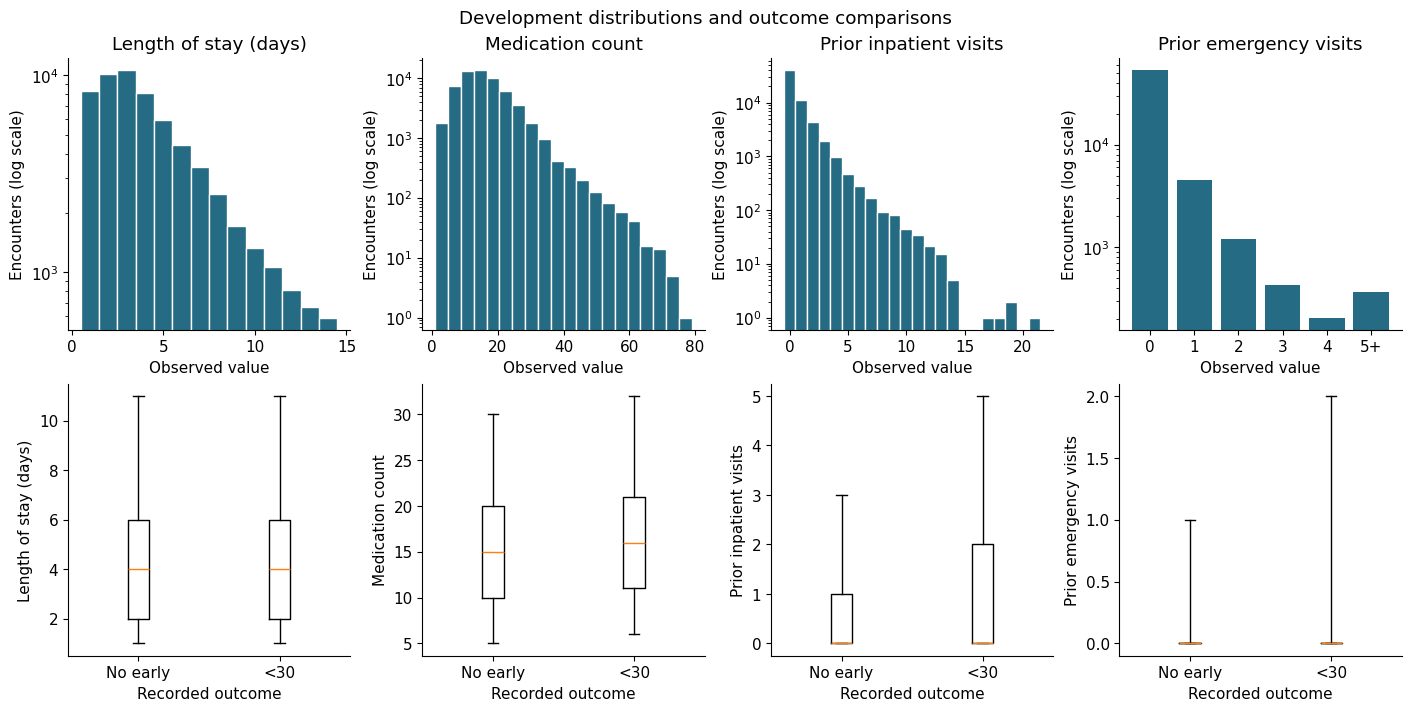

In [5]:
numeric_summary = X[numeric_features].describe(percentiles=[.25, .5, .75, .99]).T
numeric_summary['zero_percent'] = X[numeric_features].eq(0).mean() * 100
display(numeric_summary[['mean', '50%', '75%', '99%', 'max', 'zero_percent']].round(2))

key_features = ['time_in_hospital', 'num_medications', 'number_inpatient', 'number_emergency']
feature_labels = ['Length of stay (days)', 'Medication count', 'Prior inpatient visits', 'Prior emergency visits']
fig, axes = plt.subplots(2, 4, figsize=(14, 7), layout='constrained')
for i, (name, label) in enumerate(zip(key_features, feature_labels)):
    if name == 'number_emergency':
        counts = X[name].clip(upper=5).value_counts().reindex(range(6), fill_value=0)
        axes[0, i].bar(['0', '1', '2', '3', '4', '5+'], counts, color=BLUE)
    else:
        bins = 20 if name == 'num_medications' else np.arange(X[name].min() - .5, X[name].max() + 1.5)
        axes[0, i].hist(X[name], bins=bins, color=BLUE, edgecolor='white')
    axes[0, i].set(title=label, ylabel='Encounters (log scale)', xlabel='Observed value', yscale='log')
    axes[1, i].boxplot([X.loc[y.eq(0), name], X.loc[y.eq(1), name]],
                       tick_labels=['No early', '<30'], whis=(5, 95), showfliers=False)
    axes[1, i].set(xlabel='Recorded outcome', ylabel=label)
fig.suptitle('Development distributions and outcome comparisons')
fig.savefig(OUT / 'figures/02_distributions_boxplots.png', dpi=150, bbox_inches='tight')
plt.show()

Prior visits are mostly zero and have long tails. The early-readmission group has more prior inpatient visits, but the groups overlap.

## Relationships between features

Use a Spearman heatmap to check relationships between numerical features.

,feature_a,feature_b,spearman_rho,absolute_rho
2,time_in_hospital,num_medications,0.463,0.463
13,num_procedures,num_medications,0.346,0.346
0,time_in_hospital,num_lab_procedures,0.340,0.340
21,num_medications,number_diagnoses,0.291,0.291
8,num_lab_procedures,num_medications,0.249,0.249


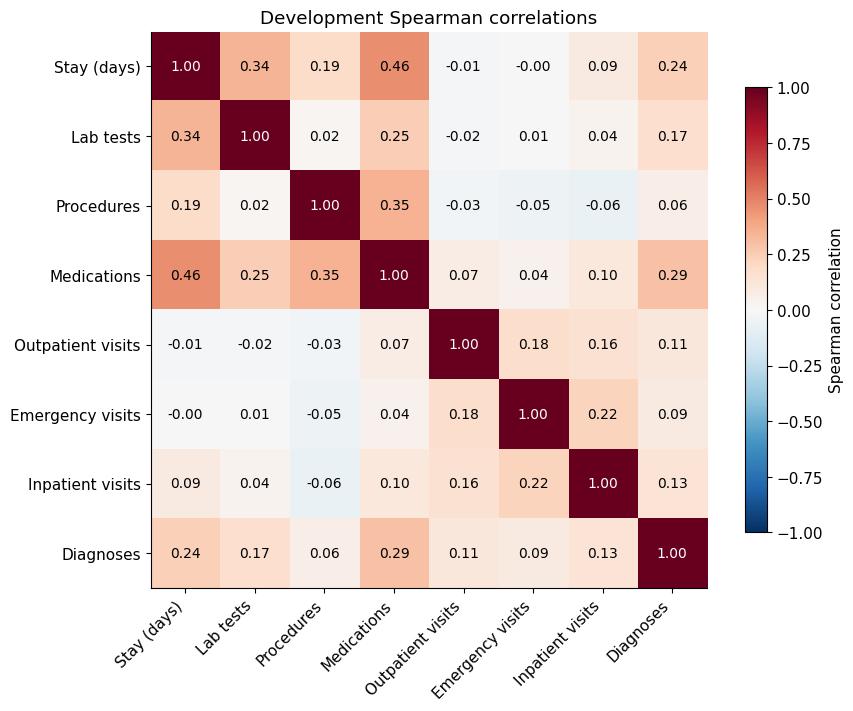

In [6]:
correlations = X[numeric_features].corr(method='spearman')
correlation_pairs = pd.DataFrame([
    {'feature_a': a, 'feature_b': b, 'spearman_rho': correlations.loc[a, b]}
    for i, a in enumerate(numeric_features) for b in numeric_features[i + 1:]
])
correlation_pairs['absolute_rho'] = correlation_pairs.spearman_rho.abs()
correlation_pairs = correlation_pairs.sort_values('absolute_rho', ascending=False)
display(correlation_pairs.head(5).round(3))

short_labels = ['Stay (days)', 'Lab tests', 'Procedures', 'Medications',
                'Outpatient visits', 'Emergency visits', 'Inpatient visits', 'Diagnoses']
fig, ax = plt.subplots(figsize=(9, 7), layout='constrained')
image = ax.imshow(correlations, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(8), short_labels, rotation=45, ha='right')
ax.set_yticks(range(8), short_labels)
for i in range(8):
    for j in range(8):
        value = correlations.iloc[i, j]
        ax.text(j, i, f'{value:.2f}', ha='center', va='center',
                color='white' if abs(value) > .65 else 'black', fontsize=10)
ax.set_title('Development Spearman correlations')
fig.colorbar(image, ax=ax, label='Spearman correlation', shrink=.8)
fig.savefig(OUT / 'figures/03_correlations.png', dpi=150, bbox_inches='tight')
plt.show()

The strongest numerical correlation is 0.463 between stay duration and medication count. No pair reaches 0.80. Check category counts alongside readmission rates.

In [7]:
a1c_outcomes = dev.groupby('A1Cresult', dropna=False).agg(
    encounters=('target', 'size'), early_readmissions=('target', 'sum'),
    early_readmission_rate=('target', 'mean'),
)
display(a1c_outcomes)

,encounters,early_readmissions,early_readmission_rate
A1Cresult,,,
>7,2263,238,0.1052
>8,4986,519,0.1041
None,49453,5783,0.1169
Norm,2968,314,0.1058


HbA1c groups have different readmission rates, but this does not prove that testing changes readmission risk.

## Screen outliers before deciding how to handle them

Use 1.5-IQR fences to flag unusual values. When IQR is zero, every positive count may be flagged.

In [8]:
q1 = X[numeric_features].quantile(.25)
q3 = X[numeric_features].quantile(.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
iqr_flags = X[numeric_features].lt(lower) | X[numeric_features].gt(upper)
outlier_summary = pd.DataFrame({
    'q1': q1, 'q3': q3, 'iqr': iqr, 'lower_fence': lower, 'upper_fence': upper,
    'flagged_encounters': iqr_flags.sum(), 'flagged_percent': iqr_flags.mean() * 100,
})
display(outlier_summary.round(2))
print(f'Encounters flagged in at least one field: {iqr_flags.any(axis=1).sum():,}')

,q1,q3,iqr,lower_fence,upper_fence,flagged_encounters,flagged_percent
time_in_hospital,2.0,6.0,4.0,-4.0,12.0,1256,2.10
num_lab_procedures,31.0,57.0,26.0,-8.0,96.0,74,0.12
num_procedures,0.0,2.0,2.0,-3.0,5.0,2894,4.85
num_medications,10.0,20.0,10.0,-5.0,35.0,1452,2.43
number_outpatient,0.0,0.0,0.0,0.0,0.0,9772,16.38
number_emergency,0.0,0.0,0.0,0.0,0.0,6709,11.24
number_inpatient,0.0,1.0,1.0,-1.5,2.5,4140,6.94
number_diagnoses,6.0,9.0,3.0,1.5,13.5,159,0.27


Encounters flagged in at least one field: 20,162


IQR flags 20,162 encounters. Keep all eligible rows because unusual visit counts may be valid.

## Preprocessing: clean the development predictors

Drop features with over 95% missing values or one constant value. Group diagnoses into broad ICD-9 categories.

In [9]:
def diagnosis_group(value):
    if pd.isna(value):
        return np.nan
    try:
        code = float(value)
    except ValueError:
        return 'Other'  # Includes V and E codes.
    if 250 <= code < 251:
        return 'Diabetes'
    for low, high, extra, label in [
        (390, 460, 785, 'Circulatory'), (460, 520, 786, 'Respiratory'),
        (520, 580, 787, 'Digestive'), (580, 630, 788, 'Genitourinary'),
        (710, 740, -1, 'Musculoskeletal'), (800, 1000, -1, 'Injury'),
        (140, 240, -1, 'Neoplasms'),
    ]:
        if low <= code < high or int(code) == extra:
            return label
    return 'Other'

X_clean = X.copy()
categorical_features = [name for name in X if name not in numeric_features]
for name in categorical_features:
    X_clean[name] = X_clean[name].map(lambda value: str(value) if pd.notna(value) else np.nan)
for name in ['diag_1', 'diag_2', 'diag_3']:
    X_clean[name] = X_clean[name].map(diagnosis_group)

too_missing = X_clean.columns[X_clean.isna().mean().gt(.95)].tolist()
constant = X_clean.columns[X_clean.nunique(dropna=False).le(1)].tolist()
dropped_features = [name for name in X_clean if name in too_missing + constant]
X_clean = X_clean.drop(columns=dropped_features)
categorical_features = [name for name in X_clean if name not in numeric_features]
display(pd.DataFrame({
    'feature': dropped_features,
    'reason': ['Over 95% missing' if name in too_missing else 'Constant in development' for name in dropped_features],
}))
print(f'Retained raw predictors: {X_clean.shape[1]}')

,feature,reason
0,weight,Over 95% missing
1,acetohexamide,Constant in development
2,examide,Constant in development
3,citoglipton,Constant in development
4,metformin-rosiglitazone,Constant in development


Retained raw predictors: 42


Dropping weight and four constant medication columns leaves 42 predictors.

## Independent feature selection with mutual information

Rank raw features against the target and select the top 20 before encoding. This method does not require a classifier.

In [10]:
mi_inputs = X_clean.apply(lambda column: pd.factorize(column)[0])
mi_scores = mutual_info_classif(mi_inputs, y, discrete_features=True, random_state=SEED)
feature_ranking = pd.DataFrame({
    'feature': X_clean.columns, 'mutual_information': mi_scores,
}).sort_values('mutual_information', ascending=False, kind='stable')
selected_features = feature_ranking.head(20)['feature'].tolist()
feature_ranking['selected'] = feature_ranking.feature.isin(selected_features)
display(feature_ranking.head(20).reset_index(drop=True))

,feature,mutual_information,selected
0,number_inpatient,0.0115,True
1,discharge_disposition_id,0.0058,True
2,number_emergency,0.0024,True
3,medical_specialty,0.0020,True
4,num_medications,0.0019,True
5,time_in_hospital,0.0017,True
6,number_diagnoses,0.0017,True
7,num_lab_procedures,0.0014,True
8,number_outpatient,0.0010,True
9,insulin,0.0008,True


Prior inpatient visits, discharge disposition, and emergency visits rank highest. These rankings show association, not causation.

## Standardize numerical features and encode categories

Use `.fillna()` with development medians for numerical values and `"Missing"` for categories. Then standardize numerical features and one-hot encode categories. Pool categories seen fewer than 25 times.

There are no numerical missing values in this run. Standardization changes scale, not skewness. Keep original counts in the main feature matrix.

In [11]:
numeric_medians = X_clean[numeric_features].median()
X_filled = X_clean.copy()
X_filled[numeric_features] = X_filled[numeric_features].fillna(numeric_medians)
X_filled[categorical_features] = X_filled[categorical_features].fillna('Missing')
assert X_filled.isna().sum().sum() == 0

preprocessor_all = ColumnTransformer([
    ('numeric', StandardScaler(), numeric_features),
    ('categorical', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=25), categorical_features),
], sparse_threshold=1.0)
X_all = preprocessor_all.fit_transform(X_filled)

selected_numeric = [name for name in numeric_features if name in selected_features]
selected_categorical = [name for name in categorical_features if name in selected_features]
preprocessor_selected = ColumnTransformer([
    ('numeric', StandardScaler(), selected_numeric),
    ('categorical', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=25), selected_categorical),
], sparse_threshold=1.0)
X_selected = preprocessor_selected.fit_transform(X_filled[selected_features])
print('All retained features after encoding:', X_all.shape)
print('Top 20 features after encoding:', X_selected.shape)
assert np.isfinite(X_all.data).all()
assert np.isfinite(X_selected.data).all()

All retained features after encoding: (59670, 216)
Top 20 features after encoding: (59670, 147)


In [12]:
fitted_numeric = preprocessor_all.named_transformers_['numeric']
scaled_numeric = fitted_numeric.transform(X_filled[numeric_features])
scaling_audit = pd.DataFrame({
    'feature': numeric_features,
    'missing_before': X_clean[numeric_features].isna().sum().to_numpy(),
    'imputation_median': numeric_medians.to_numpy(),
    'development_mean': fitted_numeric.mean_,
    'development_std': fitted_numeric.scale_,
    'mean_after': scaled_numeric.mean(axis=0),
    'std_after': scaled_numeric.std(axis=0),
})
display(scaling_audit.round(4))
np.testing.assert_allclose(scaled_numeric.mean(axis=0), 0, atol=1e-10)
np.testing.assert_allclose(scaled_numeric.std(axis=0), 1, atol=1e-10)

category_encoder = preprocessor_all.named_transformers_['categorical']
display(pd.DataFrame({
    'feature': categorical_features,
    'development_categories': [len(categories) for categories in category_encoder.categories_],
    'pooled_rare_categories': [0 if values is None else len(values) for values in category_encoder.infrequent_categories_],
}).head(12))
print('Example encoded names:', preprocessor_all.get_feature_names_out()[:12].tolist())

,feature,missing_before,imputation_median,development_mean,development_std,mean_after,std_after
0,time_in_hospital,0,4.0,4.3645,2.9528,0.0,1.0
1,num_lab_procedures,0,44.0,42.8666,19.5688,0.0,1.0
2,num_procedures,0,1.0,1.3292,1.7021,0.0,1.0
3,num_medications,0,15.0,15.9688,8.0807,0.0,1.0
4,number_outpatient,0,0.0,0.3659,1.2519,0.0,1.0
5,number_emergency,0,0.0,0.2050,1.0319,-0.0,1.0
6,number_inpatient,0,0.0,0.6372,1.2774,0.0,1.0
7,number_diagnoses,0,8.0,7.4111,1.9361,-0.0,1.0


,feature,development_categories,pooled_rare_categories
0,race,6,0
1,gender,3,1
2,age,10,0
3,admission_type_id,8,2
4,discharge_disposition_id,21,6
5,admission_source_id,16,6
6,payer_code,17,0
7,medical_specialty,68,31
8,diag_1,10,1
9,diag_2,10,0


Example encoded names: ['numeric__time_in_hospital', 'numeric__num_lab_procedures', 'numeric__num_procedures', 'numeric__num_medications', 'numeric__number_outpatient', 'numeric__number_emergency', 'numeric__number_inpatient', 'numeric__number_diagnoses', 'categorical__race_AfricanAmerican', 'categorical__race_Asian', 'categorical__race_Caucasian', 'categorical__race_Hispanic']


Encoding produces 216 columns for all features and 147 for the selected features. Scaled numerical features have means near zero and standard deviations near one.

## Dimensionality reduction with PCA

Apply PCA to the full encoded matrix and retain at least 95% of its variance. PCA does not use the target.

In [13]:
pca = PCA(n_components=.95, svd_solver='full')
X_pca = pca.fit_transform(X_all.toarray())
cumulative_variance = pca.explained_variance_ratio_.cumsum()
pca_variance = pd.DataFrame({
    'component': np.arange(1, pca.n_components_ + 1),
    'variance_ratio': pca.explained_variance_ratio_,
    'cumulative_variance': cumulative_variance,
})
print(f'PCA dimensions: {X_all.shape[1]} -> {X_pca.shape[1]}')
print(f'Retained variance: {cumulative_variance[-1]:.2%}')
print(f'Variance in the first two components: {cumulative_variance[1]:.2%}')
assert cumulative_variance[-1] >= .95
assert np.isfinite(X_pca).all()

PCA dimensions: 216 -> 65
Retained variance: 95.11%
Variance in the first two components: 19.15%


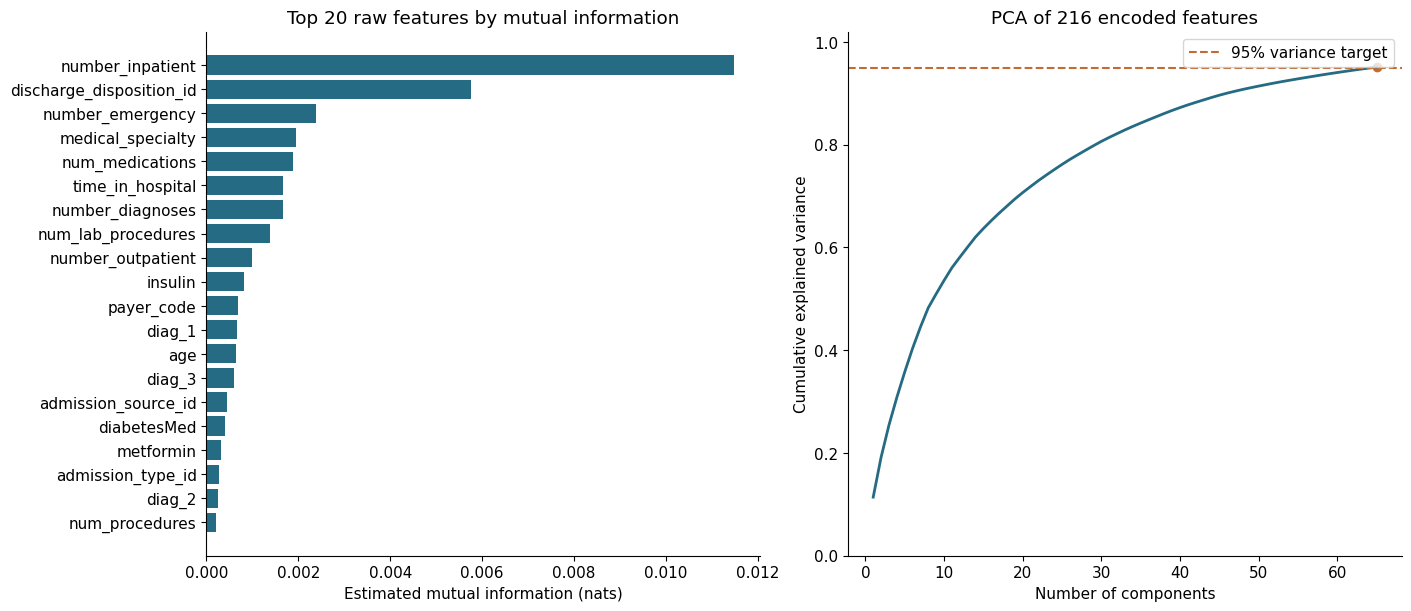

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), layout='constrained')
top_features = feature_ranking.head(20).iloc[::-1]
axes[0].barh(top_features.feature, top_features.mutual_information, color=BLUE)
axes[0].set(title='Top 20 raw features by mutual information', xlabel='Estimated mutual information (nats)')
axes[1].plot(pca_variance.component, pca_variance.cumulative_variance, color=BLUE, linewidth=2)
axes[1].axhline(.95, color=ORANGE, linestyle='--', label='95% variance target')
axes[1].scatter([pca.n_components_], [cumulative_variance[-1]], color=ORANGE)
axes[1].set(title=f'PCA of {X_all.shape[1]} encoded features', xlabel='Number of components',
            ylabel='Cumulative explained variance', ylim=(0, 1.02))
axes[1].legend()
fig.savefig(OUT / 'figures/04_feature_selection_pca.png', dpi=150, bbox_inches='tight')
plt.show()

PCA keeps 65 components and 95.11% of variance. Retained variance is not prediction accuracy.

## Data augmentation and imbalance

Do not add synthetic rows or oversample here. Any later resampling must happen inside training folds.

## Save EDA tables

Save the EDA results and preprocessing checks as CSV tables. Refit preprocessing inside each training fold when building models.

In [15]:
missingness.to_csv(OUT / 'tables/missingness.csv')
coded_unknowns.to_csv(OUT / 'tables/coded_unknowns.csv', index=False)
numeric_summary.to_csv(OUT / 'tables/numeric_summary.csv')
correlation_pairs.to_csv(OUT / 'tables/correlation_pairs.csv', index=False)
outlier_summary.to_csv(OUT / 'tables/outlier_summary.csv')
scaling_audit.to_csv(OUT / 'tables/scaling_audit.csv', index=False)
feature_ranking.to_csv(OUT / 'tables/feature_selection.csv', index=False)
pca_variance.to_csv(OUT / 'tables/pca_variance.csv', index=False)
print('Saved EDA tables to notebooks/outputs/tables/')

Saved EDA tables to notebooks/outputs/tables/


## Save the report

Save a short report using the results and four figures above.

In [16]:
report = f"""# Section 3: exploratory analysis and preprocessing

## Data and methods
We analyzed {len(dev):,} development encounters from {dev.patient_nbr.nunique():,} patients.
The target was recorded readmission in the released <30 category, with >30 and NO as negatives.
Patients were separated before analysis; calibration and test patients remained reserved.
We examined missingness, distributions, outcome comparisons, and Spearman correlations.

## Main findings
Early readmission occurred in {y.mean():.2%} of development encounters. Weight was
{missingness.loc['weight', 'missing_percent']:.2f}% missing. Prior hospital use was
concentrated at zero with a long upper tail. The strongest numerical correlation was
{correlation_pairs.iloc[0].spearman_rho:.3f}, between length of stay and medication count.
These results support attention to class imbalance, missingness, and unusual utilization.
Category-level outcome comparisons were unadjusted and did not establish causation.

![Class balance and missingness](figures/01_class_balance_missingness.png)
![Distributions and outcome boxplots](figures/02_distributions_boxplots.png)
![Numerical correlations](figures/03_correlations.png)

## Preprocessing decisions
We removed features above 95% missingness and development-constant features, retaining
{X_clean.shape[1]} raw predictors. We preserved laboratory None and coded unknown categories,
and used .fillna() with development medians for numerical values and Missing for categories.
No numerical values needed filling in this run.
We standardized numerical inputs and one-hot encoded categorical inputs, pooling categories
with fewer than 25 development occurrences. This produced {X_all.shape[1]} encoded columns.

IQR flagged {iqr_flags.any(axis=1).sum():,} encounters. We retained every eligible encounter because unusual values
were not confirmed errors. No data augmentation or oversampling was performed.

## Feature selection and dimensionality reduction
An independent mutual-information filter selected {len(selected_features)} raw predictors,
producing {X_selected.shape[1]} encoded columns. Prior inpatient visits, discharge disposition,
and emergency visits ranked highest. Separately, PCA retained {pca.n_components_} components
explaining {cumulative_variance[-1]:.2%} of the full encoded variance. This measures retained
representation variance, not classification accuracy. Every learned step must be refitted
inside each training fold for later cross-validation.

![Mutual information and PCA](figures/04_feature_selection_pca.png)

## Limitations
Encounters came from historical US records and may miss readmissions elsewhere.
Repeated encounters are correlated within patients. The source does not support reliable
chronological or hospital holdouts. Our findings are descriptive and do not establish
intervention effects or clinical readiness.

## Sources
- Clore et al. (2014). UCI Diabetes 130-US Hospitals. https://doi.org/10.24432/C5230J
- scikit-learn documentation: https://scikit-learn.org/1.7/modules/preprocessing.html
- Mutual information: https://scikit-learn.org/1.7/modules/generated/sklearn.feature_selection.mutual_info_classif.html
- PCA: https://scikit-learn.org/1.7/modules/generated/sklearn.decomposition.PCA.html
"""
# Remove indentation used to keep this notebook cell readable.
report = '\n'.join(line.strip() for line in report.splitlines())
(OUT / 'section3_report.md').write_text(report)
print('Saved notebooks/outputs/section3_report.md')

Saved notebooks/outputs/section3_report.md


## References

- [UCI dataset](https://doi.org/10.24432/C5230J).
- scikit-learn: [preprocessing](https://scikit-learn.org/1.7/modules/preprocessing.html), [mutual information](https://scikit-learn.org/1.7/modules/generated/sklearn.feature_selection.mutual_info_classif.html), and [PCA](https://scikit-learn.org/1.7/modules/generated/sklearn.decomposition.PCA.html).